# 20. GTX-A 접근성 × 경쟁 목적지 비율 4유형 분석

**목적:** 개통 전 교통환경으로 구분한 유형에서 실제 광역버스 수요 변화가 다르게 나타나는지, 그 방향이 세 역에서 반복되는지 먼저 확인한다. 예측모형 적합이나 GTX-C 적용은 하지 않는다.

분석대상은 기존 공급구조 유지 250m 격자 126개다. 기존 OLS를 수정하지 않는다. 2024-10-17·2025-11-06 합성자료의 관찰된 차이이며 인과효과가 아니다.

## 기준을 결과와 분리해서 정함

1. 전체126의 보행시간 중앙값 **47.604분 이하/초과**: 절대적인 ‘접근성 좋음/나쁨’ 대신 **상대적으로 짧음/긺**이라고 부른다. 47분도 긴 보행시간일 수 있다. 기준은 각 역에서 따로 구하지 않는다.
2. 경쟁 비율은 **양수/0**: 126개 중 78개가 0으로 전체 중앙값도 0이다. 이를 일반적인 ‘높음/낮음’이라고 과장하지 않는다.
3. 경쟁 비율 0은 현재 구축값이 0임을 뜻한다. 원자료에서 분류 가능한 하차좌표가 없을 때도 0으로 처리되는 경로가 있으므로, 실제 경쟁 수요 부재로 확정하려면 원자료 유효 수요를 확인해야 한다.
4. 기존 보행20분 기준은 전체11개, 대곡1개에 불과해 4유형을 역별로 비교하기 어렵다. 이 기준의 교차표도 함께 제시한다. 결과가 좋아지는 문턱값을 탐색하지 않는다.
5. 유형화는 보행·경쟁 원 단위의 구분이며 로그 여부는 이 기준에 적용하지 않는다. 전후 승차량으로 유형을 결정하지 않는다.

유형 A=짧음·경쟁양수, B=짧음·경쟁0, C=긺·경쟁양수, D=긺·경쟁0.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import importlib.util
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
paths=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(),Path.cwd()/'analysis',Path.cwd()/'gtx_a_bus_analysis'/'analysis',Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in paths if (p/'20_GTX-A_접근성_경쟁목적지_유형분석.py').exists()),None)
if ANALYSIS is None:raise FileNotFoundError('프로젝트 또는 analysis 폴더에서 실행하세요.')
spec=importlib.util.spec_from_file_location('type_experiment',next((UROP_ROOT / 'code').rglob('20_GTX-A_접근성_경쟁목적지_유형분석.py')))
experiment=importlib.util.module_from_spec(spec);spec.loader.exec_module(experiment)
fonts={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fonts),None)
if font:plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'font.size':11,'figure.dpi':110})
pd.set_option('display.max_columns',25)
data,definition,counts,tables,contrasts,twenty,totals=experiment.analyze()
display(definition)
display(counts)
print('기존20分 기준으로 나누었을 때:')
display(twenty)
print('기초0명:',int((data.board_2024_all==0).sum()),'| 회귀 아님, 유형별 관찰 결과 비교')

기존20分 기준으로 나누었을 때:
기초0명: 0 | 회귀 아님, 유형별 관찰 결과 비교


,유형,설명,보행기준,경쟁기준
0,A,상대짧음·경쟁양수,≤ 47.604분,> 0%
1,B,상대짧음·경쟁0,≤ 47.604분,= 0%
2,C,상대긺·경쟁양수,> 47.604분,> 0%
3,D,상대긺·경쟁0,> 47.604분,= 0%


유형,A,B,C,D
nearest_station,,,,
운정중앙,6,18,12,27
킨텍스,7,9,9,1
대곡,10,13,4,10


col_0,A,B,C,D
nearest_station,,,,
운정중앙,3,3,15,42
킨텍스,1,3,15,7
대곡,0,1,14,22


## 1. 유형별 실제 변화

R_i는 격자 변화율, Y=R_i−R_s는 권역 전체 대비 변화율 차이(%p)다. 권역 R_s는 원래126개로 고정한다.

- **격자 평균·중앙값:** 각 격자를 같은 단위로 본다. 평균은 작은 분모의 극단값에 민감하다.
- **총량 변화율:** 같은 유형의 승차인원을 합쳐 전후 비교한다. 큰 수요 격자의 영향이 크다.
- **Y 가중평균:** 개통 전 승차량으로 Y를 가중한 값. 한 역 안에서는 유형 총량 변화율−그 역 전체 변화율과 같다. 여러 역을 합친 행에서는 역별 R_s를 각각 적용한 가중평균이며 전체A 총량 변화율을 뺀 값과 같지 않을 수 있다.
- n<5는 해석 주의 표시다. 기초승차량이 작다는 이유만으로 본 분석에서 제외하지 않는다.

,권역,유형,n,기초승차중앙값,기초10미만,승차전,승차후,변화율평균(%),변화율중앙값(%),총량변화율(%),Y평균(%p),Y중앙값(%p),Y가중평균(%p),소표본주의(n<5)
0,전체,A,23,146.0,0,8525.0,2572.0,-68.556,-70.909,-69.830,-2.296,-4.787,-1.365,False
1,전체,B,40,75.0,4,5891.0,1834.0,-66.474,-68.966,-68.868,0.873,-0.917,0.255,False
2,전체,C,25,47.0,5,2009.0,610.0,-65.478,-70.690,-69.637,3.294,-2.680,-1.273,False
3,전체,D,38,14.0,15,1469.0,569.0,-35.022,-56.316,-61.266,33.065,10.905,8.642,False


,권역,유형,n,기초승차중앙값,기초10미만,승차전,승차후,변화율평균(%),변화율중앙값(%),총량변화율(%),Y평균(%p),Y중앙값(%p),Y가중평균(%p),소표본주의(n<5)
4,대곡,A,10,100.0,0,1472.0,621.0,-59.059,-61.050,-57.812,2.192,0.201,3.438,False
5,대곡,B,13,51.0,2,687.0,231.0,-63.320,-62.500,-66.376,-2.069,-1.249,-5.125,False
6,대곡,C,4,44.5,1,361.0,118.0,-63.163,-66.419,-67.313,-1.912,-5.168,-6.062,True
7,대곡,D,10,5.0,6,102.0,46.0,-16.252,-55.000,-54.902,44.999,6.251,6.349,False
8,운정중앙,A,6,217.5,0,2044.0,594.0,-76.437,-77.630,-70.939,-5.878,-7.070,-0.380,False
9,운정중앙,B,18,103.5,2,2707.0,677.0,-73.681,-72.554,-74.991,-3.122,-1.995,-4.432,False
10,운정중앙,C,12,22.5,4,382.0,120.0,-63.120,-72.517,-68.586,7.440,-1.958,1.973,False
11,운정중앙,D,27,18.0,8,1358.0,520.0,-40.802,-52.632,-61.708,29.757,17.928,8.851,False
12,킨텍스,A,7,593.0,0,5009.0,1357.0,-75.368,-76.316,-72.909,-5.638,-6.586,-3.179,False
13,킨텍스,B,9,79.0,0,2497.0,926.0,-56.615,-64.557,-62.915,13.115,5.173,6.815,False


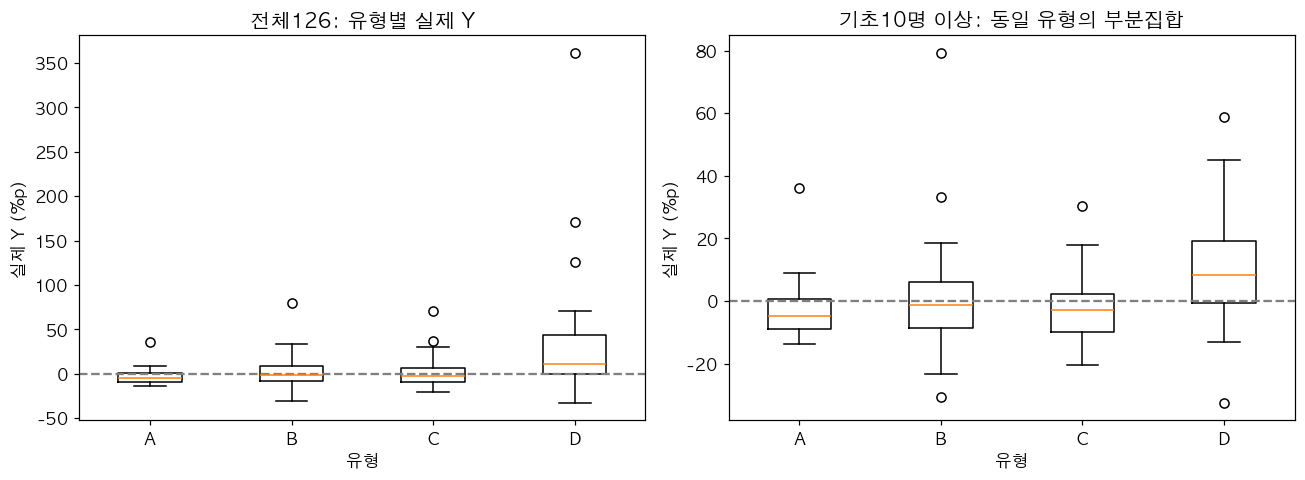

In [2]:
columns=['권역','유형','n','기초승차중앙값','기초10미만','승차전','승차후','변화율평균(%)','변화율중앙값(%)','총량변화율(%)','Y평균(%p)','Y중앙값(%p)','Y가중평균(%p)','소표본주의(n<5)']
whole=tables[tables['기초기준']==0]
display(whole[whole['권역']=='전체'][columns].round(3))
display(whole[whole['권역']!='전체'][columns].round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,minimum,title in [(axes[0],0,'전체126: 유형별 실제 Y'),(axes[1],10,'기초10명 이상: 동일 유형의 부분집합')]:
 sub=data[data.board_2024_all>=minimum]
 arrays=[sub.loc[sub['유형']==t,'Y'].to_numpy() for t in experiment.ORDER]
 ax.boxplot(arrays,labels=experiment.ORDER,showfliers=True)
 ax.axhline(0,color='gray',ls='--');ax.set(xlabel='유형',ylabel='실제 Y (%p)',title=title)
plt.tight_layout();plt.show()

## 2. 세 역의 방향이 같은가?

동일한 대비를 역마다 확인한다. 예를 들어 A−C는 경쟁 비율 양수인 격자 중 상대적으로 보행이 짧은 집단과 긴 집단의 차이다. 부호가 바뀌면 하나의 유형 규칙으로 다른 지역에 옮기기 어렵다. 부호가 같아도 소표본·교란요인이 있으므로 재현 입증은 아니다. 공간적으로 독립하지 않은126개를 독립 표본으로 간주하는 단순 유의성 검정은 하지 않는다.

,기초기준,권역,대비,왼쪽n,오른쪽n,Y중앙값차이(%p),Y가중평균차이(%p)
0,0,전체,경쟁양수에서_짧음-긺,23,25,-2.107,-0.093
1,0,전체,경쟁0에서_짧음-긺,40,38,-11.822,-8.387
2,0,전체,보행짧음에서_경쟁양수-0,23,40,-3.869,-1.620
3,0,전체,보행긺에서_경쟁양수-0,25,38,-13.585,-9.914
4,0,대곡,경쟁양수에서_짧음-긺,10,4,5.369,9.501
5,0,대곡,경쟁0에서_짧음-긺,13,10,-7.500,-11.474
6,0,대곡,보행짧음에서_경쟁양수-0,10,13,1.450,8.563
7,0,대곡,보행긺에서_경쟁양수-0,4,10,-11.419,-12.411
8,0,운정중앙,경쟁양수에서_짧음-긺,6,12,-5.112,-2.353
9,0,운정중앙,경쟁0에서_짧음-긺,18,27,-19.922,-13.282


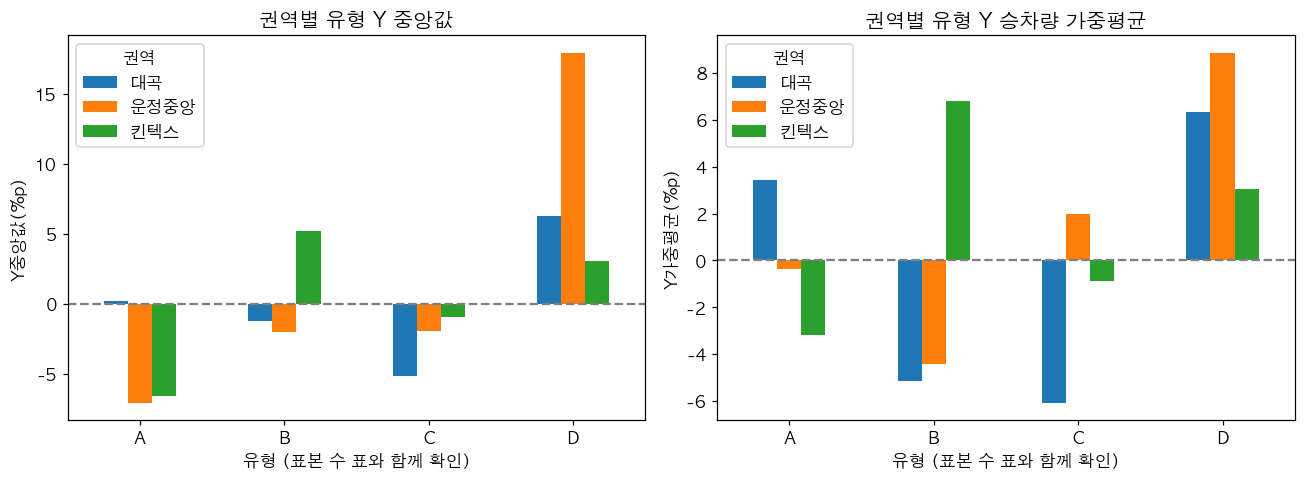

In [3]:
display(contrasts[contrasts['기초기준']==0].round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric,title in [(axes[0],'Y중앙값(%p)','권역별 유형 Y 중앙값'),(axes[1],'Y가중평균(%p)','권역별 유형 Y 승차량 가중평균')]:
 view=whole[whole['권역']!='전체'].pivot(index='유형',columns='권역',values=metric).reindex(experiment.ORDER)
 view.plot.bar(ax=ax)
 ax.axhline(0,color='gray',ls='--');ax.set(xlabel='유형 (표본 수 표와 함께 확인)',ylabel=metric,title=title);ax.tick_params(axis='x',rotation=0)
plt.tight_layout();plt.show()

## 3. 소규모 격자의 영향과 기준의 한계

5명/10명 이상 결과는 **유형 문턱값·권역 기준을 바꾸지 않은 기술통계**다. 좋은 결과가 나오는 부분집합을 최종 선택하지 않는다. 유형별 개통 전 승차규모 자체가 다른 점도 함께 확인해야 한다.

기초 5명 이상, 유형은 원래126개 기준 고정
기초 10명 이상, 유형은 원래126개 기준 고정
10명 이상 역별 표본 수:


,권역,유형,n,기초승차중앙값,기초10미만,승차전,승차후,변화율평균(%),변화율중앙값(%),총량변화율(%),Y평균(%p),Y중앙값(%p),Y가중평균(%p),소표본주의(n<5)
16,전체,A,23,146.0,0,8525.0,2572.0,-68.556,-70.909,-69.830,-2.296,-4.787,-1.365,False
17,전체,B,38,83.0,2,5884.0,1831.0,-66.902,-70.110,-68.882,0.521,-1.194,0.245,False
18,전체,C,22,63.5,2,1998.0,604.0,-67.967,-71.242,-69.770,0.983,-1.958,-1.404,False
19,전체,D,29,19.0,6,1446.0,548.0,-52.788,-60.000,-62.102,16.138,9.448,7.885,False


,권역,유형,n,기초승차중앙값,기초10미만,승차전,승차후,변화율평균(%),변화율중앙값(%),총량변화율(%),Y평균(%p),Y중앙값(%p),Y가중평균(%p),소표본주의(n<5)
32,전체,A,23,146.0,0,8525.0,2572.0,-68.556,-70.909,-69.830,-2.296,-4.787,-1.365,False
33,전체,B,36,88.0,0,5870.0,1825.0,-67.162,-70.110,-68.910,0.345,-1.194,0.228,False
34,전체,C,20,73.5,0,1984.0,596.0,-70.097,-72.517,-69.960,-1.307,-3.017,-1.609,False
35,전체,D,23,31.0,0,1403.0,516.0,-58.721,-61.111,-63.222,10.220,8.364,6.794,False


유형,A,B,C,D
nearest_station,,,,
운정중앙,6,16,8,19
킨텍스,7,9,9,0
대곡,10,11,3,4


,기초기준,권역,대비,왼쪽n,오른쪽n,Y중앙값차이(%p),Y가중평균차이(%p)
36,10,대곡,경쟁양수에서_짧음-긺,10,3,5.121,9.506
37,10,대곡,경쟁0에서_짧음-긺,11,4,-7.791,-5.790
38,10,대곡,보행짧음에서_경쟁양수-0,10,11,1.740,8.953
39,10,대곡,보행긺에서_경쟁양수-0,3,4,-11.171,-6.343
40,10,운정중앙,경쟁양수에서_짧음-긺,6,8,-4.053,-0.662
41,10,운정중앙,경쟁0에서_짧음-긺,16,19,-10.359,-11.630
42,10,운정중앙,보행짧음에서_경쟁양수-0,6,16,-5.076,4.051
43,10,운정중앙,보행긺에서_경쟁양수-0,8,19,-11.381,-6.917
44,10,킨텍스,경쟁양수에서_짧음-긺,7,9,-5.626,-2.293
45,10,킨텍스,보행짧음에서_경쟁양수-0,7,9,-11.759,-9.993


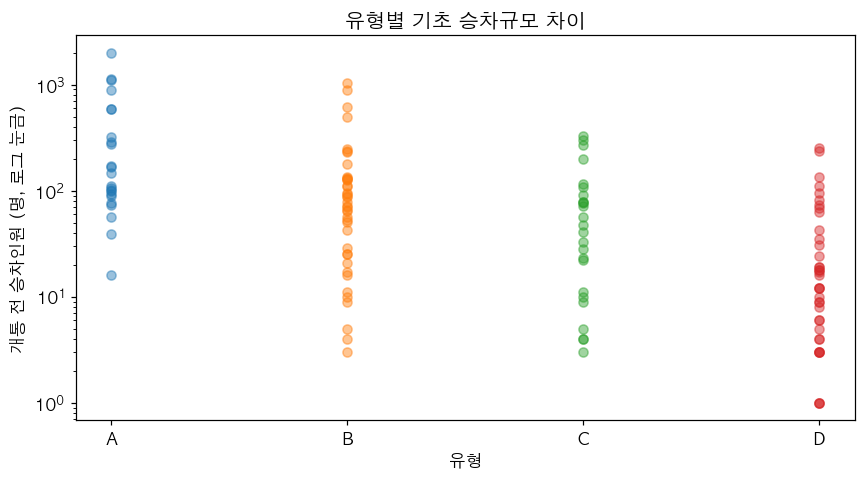

In [4]:
for minimum in [5,10]:
 print(f'기초 {minimum}명 이상, 유형은 원래126개 기준 고정')
 display(tables[(tables['기초기준']==minimum)&(tables['권역']=='전체')][columns].round(3))
print('10명 이상 역별 표본 수:')
display(pd.crosstab(data.loc[data.board_2024_all>=10,'nearest_station'],data.loc[data.board_2024_all>=10,'유형']).reindex(index=experiment.base.STATIONS,columns=experiment.ORDER,fill_value=0))
display(contrasts[(contrasts['기초기준']==10)&(contrasts['권역']!='전체')].round(3))
fig,ax=plt.subplots(figsize=(8,4.5))
for t in experiment.ORDER:
 values=data.loc[data['유형']==t,'board_2024_all']
 ax.scatter(np.full(len(values),experiment.ORDER.index(t)),values,alpha=.45,label=t)
ax.set_xticks(range(4),experiment.ORDER);ax.set_yscale('log');ax.set(xlabel='유형',ylabel='개통 전 승차인원 (명, 로그 눈금)',title='유형별 기초 승차규모 차이')
plt.tight_layout();plt.show()

## 4. 이번 결과의 해석 (2026-10-17)

- 전체 유형 수는 A23/B40/C25/D38개. 유형별 Y 중앙값은 **A−4.79/B−0.92/C−2.68/D+10.91%p**. 전체로 합치면 D의 상대적 감소가 작은 양상이 보인다.
- 그러나 D의 기초승차 중앙값은14명이고 38개 중15개가10명 미만이다. 단순 평균 Y+33.07%p는 극단값에 민감하다. 10명 이상 D23개에서도 Y 중앙값+8.36%p는 남지만, 그23개는 운정중앙19개·대곡4개로 킨텍스는 없다.
- 킨텍스 D유형은 원래부터1개뿐이고, 대곡 C유형은4개다. 따라서 네 유형 모두의 경향이 세 역에서 반복되는지 충분히 평가할 수 없다.
- A−C의 Y 중앙값 차이는 운정중앙−5.11/킨텍스−5.63%p지만 대곡은+5.37%p로 방향이 반대다. 짧은 보행이면 일관되게 더 감소한다고 결론 내릴 수 없다.
- 경쟁양수 A와 경쟁0 B의 Y 가중평균 대비도 대곡+8.56/운정중앙+4.05/킨텍스−9.99%p로 방향이 달랐다. 중앙값과 가중평균의 메시지가 다를 수 있다.
- **일부 공간적 패턴은 탐색됐지만, 네 유형의 수요 변화가 세 역에서 일관되게 구분된다고 확인되지는 않았다.** 따라서 이 기준으로 GTX-C 미래 수요 유형을 확정하거나 평균 감소율을 옮기지 않는다.
- 경쟁0의 자료 품질, 노선·목적지 구성, 기초승차규모 차이를 추가 확인할 수 있지만, 유형 기준을 계속 바꿔 원하는 결과를 찾는 방식은 사용하지 않는다. 기존 OLS 결과를 대체하거나 인과효과를 입증하는 분석이 아니다.